# Supplementary Figure S15b-c. Indirect associations through and onto INO80E

Bootstrap mediation at the 16p11.2 AD colocalization: (b) INO80E (context in brackets after "via") as mediator of the genotype effect on other local cis-eGenes; (c) other local cis-eGenes as mediators and INO80E as outcome. Points are raw indirect effect estimates and horizontal bars 95% percentile donor-bootstrap confidence intervals (1000 replicates).

Selection / statistical note: the source table (`bidirectional_bootstrap_indirect_95CI_nominal29.tsv`) contains only the 29 mediator-outcome pairs whose 95% CI excludes zero, selected from a larger screen of cis-cis pairs (the full screen table was not found). These are nominal results: bootstrap p ranges up to 0.052 and the smallest BH q is 0.26 (`BH_q`), so none survives multiple-testing correction.

Inputs: `data/Figure_S15b_INO80E_as_mediator.rds`, `data/Figure_S15c_INO80E_as_outcome.rds`


In [1]:
library(ggplot2)
library(patchwork)
b <- readRDS("data/Figure_S15b_INO80E_as_mediator.rds")
c15 <- readRDS("data/Figure_S15c_INO80E_as_outcome.rds")
b[, c("label", "indirect_effect", "ci_lower", "ci_upper", "bootstrap_p", "BH_q", "n_complete")]
c15[, c("label", "indirect_effect", "ci_lower", "ci_upper", "bootstrap_p", "BH_q", "n_complete")]

label,indirect_effect,ci_lower,ci_upper,bootstrap_p,BH_q,n_complete
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
MAPK3 (DLPFC) via INO80E (DLPFC),-0.031110562,-4.627037e-02,-0.0155279691,0.001998002,0.2587413,784
KCTD13 (Oli) via INO80E (Ast),0.030746491,7.719035e-03,0.0601430292,0.005994006,0.5174825,386
KCTD13 (Ast) via INO80E (Exc),-0.030176493,-5.844659e-02,-0.0025031476,0.035964036,0.7678773,386
DOC2A (AC) via INO80E (Exc),-0.029234331,-6.110354e-02,-0.0007954071,0.041958042,0.7678773,305
SEZ6L2 (Oli) via INO80E (Oli),-0.027519277,-5.691415e-02,-0.0030869746,0.019980020,0.7678773,386
MAPK3 (PCC) via INO80E (Ast),-0.022474404,-4.630968e-02,-0.0007357737,0.041958042,0.7678773,234
ASPHD1 (AC) via INO80E (DLPFC),0.015491640,1.360546e-03,0.0296748216,0.029970030,0.7678773,548
YPEL3 (DLPFC) via INO80E (DLPFC),0.013791207,5.330576e-03,0.0216993759,0.001998002,0.2587413,784
ASPHD1 (AC) via INO80E (Oli),-0.013231174,-3.067312e-02,-0.0001221990,0.049950050,0.7678773,305


label,indirect_effect,ci_lower,ci_upper,bootstrap_p,BH_q,n_complete
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
INO80E (Ast) via KCTD13 (Oli),-0.068977869,-0.1176247426,-0.0230046653,0.003996004,0.3449883,386
INO80E (Oli) via SEZ6L2 (Oli),0.058697569,0.0074457058,0.1123789218,0.021978022,0.7392607,386
INO80E (Ast) via MAPK3 (PCC),-0.052114514,-0.1087378464,-0.0011101163,0.045954046,0.7392607,234
INO80E (Inh) via KCTD13 (Oli),0.045393395,0.0012952062,0.0970614679,0.039960040,0.7392607,386
INO80E (Exc) via KCTD13 (Ast),-0.038193362,-0.0738626314,-0.0021852791,0.041958042,0.7392607,386
INO80E (Mic) via TMEM219 (AC),-0.037071359,-0.0766008955,-0.0022282369,0.043956044,0.7392607,305
INO80E (Ast) via YPEL3 (Exc),0.024116567,0.0037500065,0.0497008698,0.015984016,0.7392607,386
INO80E (Oli) via ASPHD1 (AC),0.018810263,0.0004243454,0.0470846574,0.045954046,0.7392607,305
INO80E (Mic) via PPP4C (AC),0.018276575,0.0003956639,0.0431622777,0.049950050,0.7392607,305


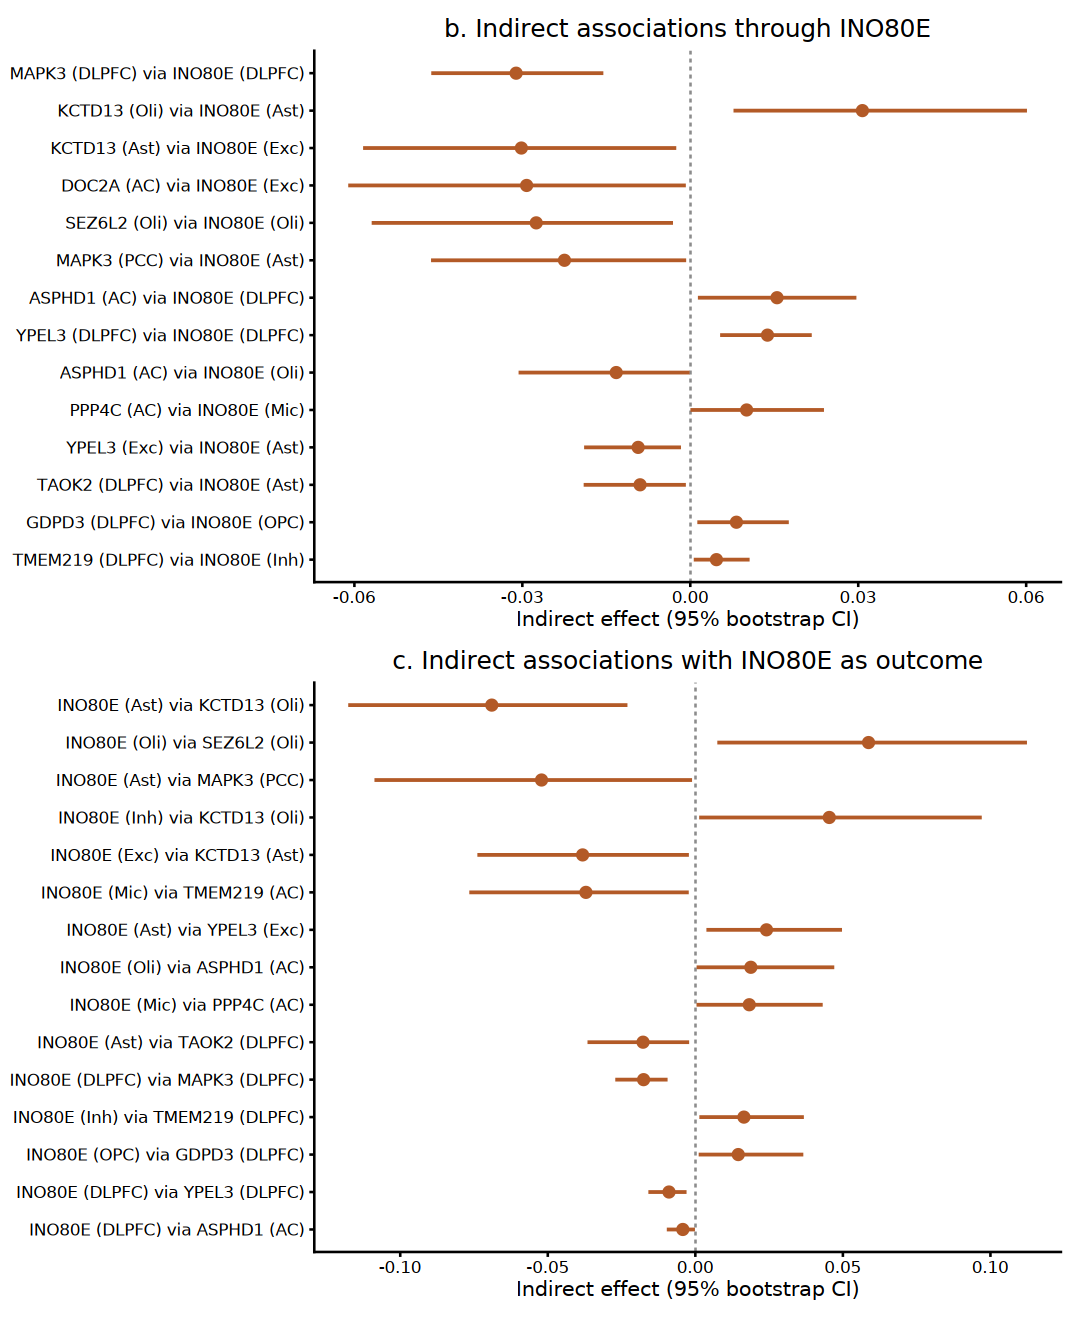

In [2]:
forest <- function(d, title) {
  d$label <- factor(d$label, levels = rev(d$label))
  ggplot(d, aes(indirect_effect, label)) +
    geom_vline(xintercept = 0, linetype = 2, colour = "grey55") +
    geom_errorbar(aes(xmin = ci_lower, xmax = ci_upper), orientation = "y", width = 0,
                  linewidth = 0.8, colour = "#B35A27") +
    geom_point(size = 2.6, colour = "#B35A27") +
    labs(title = title, x = "Indirect effect (95% bootstrap CI)", y = NULL) +
    theme_classic(base_size = 12) +
    theme(plot.title = element_text(hjust = 0.5))
}
p <- forest(b, "b. Indirect associations through INO80E") /
     forest(c15, "c. Indirect associations with INO80E as outcome") +
  plot_layout(heights = c(14, 15))
options(repr.plot.width = 9, repr.plot.height = 11)
p